# Аналитика звонка

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SergeyShk/Speech-to-Text-Russian/blob/master/notebooks/02_call_analytics.ipynb)

Что можно узнать о разговоре по результату распознавания стереозаписи, где каждый канал - свой говорящий: кто сколько говорит, паузы и время реакции, поддакивания и перебивания, темп речи, поиск ключевых фраз и сводная таблица по папке звонков.

## Установка

В Colab ячейка ставит stt-ru и `pandas`, `matplotlib`; в окружении, где пакет уже есть, ничего не делает.

In [1]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("stt_ru") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "stt-ru[ffmpeg]", "pandas", "matplotlib"],
        check=True,
    )

## Звонок

Запись из тестов проекта: оператор в канале 1, клиент в канале 0. Для своих звонков замените `CALL` и словарь ролей `ROLES`.

In [2]:
import urllib.request
from pathlib import Path

DATA = Path("data")
DATA.mkdir(exist_ok=True)
CALL = DATA / "call.wav"
if not CALL.exists():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/SergeyShk/Speech-to-Text-Russian/master/tests/data/call.wav",
        CALL,
    )

In [3]:
import re
import shutil

import matplotlib.pyplot as plt
import pandas as pd

from stt_ru import Transcriber
from stt_ru.evaluation import normalize

pd.set_option("display.max_colwidth", None)

ROLES = {0: "Клиент", 1: "Оператор"}
COLORS = {0: "tab:orange", 1: "tab:purple"}

transcriber = Transcriber()
result = transcriber.transcribe(CALL)
calls = pd.DataFrame(
    [
        {"start": s.start, "end": s.end, "channel": s.channel, "text": s.text}
        for s in result.segments
    ]
)
calls["role"] = calls["channel"].map(ROLES)
calls["duration"] = calls["end"] - calls["start"]
calls["words"] = calls["text"].str.split().str.len()
calls

,start,end,channel,text,role,duration,words
0,0.994,9.054,1,"Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии.",Оператор,8.060,21
1,3.490,3.934,0,Угу,Клиент,0.444,1
2,7.682,8.222,0,Угу,Клиент,0.540,1
3,9.634,12.638,1,"Я в свою очередь с вами прощаюсь. Всего доброго, до свидания.",Оператор,3.004,11
4,12.994,13.662,0,До свидания.,Клиент,0.668,2


## Лента разговора

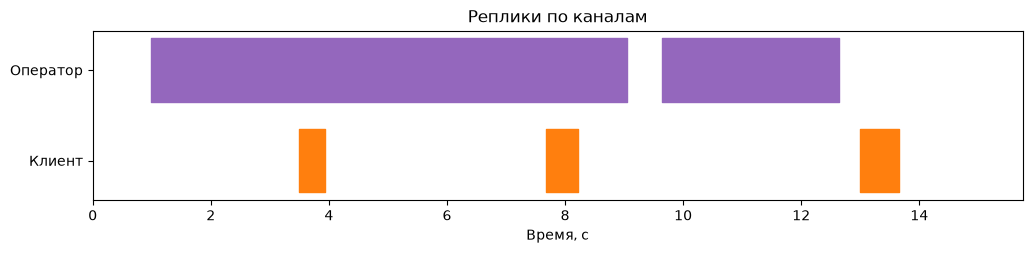

In [4]:
fig, ax = plt.subplots(figsize=(12, 2.2))
for row, channel in enumerate(ROLES):
    part = calls[calls["channel"] == channel]
    bars = list(zip(part["start"], part["duration"], strict=True))
    ax.broken_barh(bars, (row - 0.35, 0.7), color=COLORS[channel])
ax.set_yticks(range(len(ROLES)), list(ROLES.values()))
ax.set_xlim(0, result.duration)
ax.set_xlabel("Время, с")
ax.set_title("Реплики по каналам")
plt.show()

## Кто сколько говорит

Время речи - сумма длительностей фрагментов, темп - слов в минуту речи. Тишина - время, когда не говорит никто.

In [5]:
def merge(intervals):
    """Объединение пересекающихся отрезков времени"""
    merged = []
    for start, end in sorted(intervals):
        if merged and start <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], end)
        else:
            merged.append([start, end])
    return merged


talk = calls.groupby("role").agg(
    replies=("text", "size"), seconds=("duration", "sum"), words=("words", "sum")
)
talk["share"] = talk["seconds"] / result.duration
talk["wpm"] = talk["words"] / (talk["seconds"] / 60)
speech = sum(end - start for start, end in merge(zip(calls["start"], calls["end"], strict=True)))
print(
    f"Длительность звонка: {result.duration:.1f} с, речь: {speech:.1f} с, тишина: {result.duration - speech:.1f} с"
)
talk.rename(
    columns={
        "replies": "Реплик",
        "seconds": "Речь, с",
        "words": "Слов",
        "share": "Доля звонка",
        "wpm": "Слов в минуту",
    }
).round(2)

Длительность звонка: 15.8 с, речь: 11.7 с, тишина: 4.0 с


,Реплик,"Речь, с",Слов,Доля звонка,Слов в минуту
role,,,,,
Клиент,3,1.65,4,0.1,145.28
Оператор,2,11.06,32,0.7,173.54


## Реакция, поддакивания и перебивания

Для каждой реплики, которая следует за репликой другого говорящего, считается пауза между ними: положительная - время реакции, отрицательная - речь одновременно. Короткая реплика целиком внутри чужой - поддакивание («угу», «да»), а реплика, которая начинается раньше конца чужой и заканчивается позже, - перебивание.

In [6]:
def kind(row, others):
    inside = others[(others["start"] <= row["start"]) & (others["end"] >= row["end"])]
    if not inside.empty:
        return "поддакивание" if row["duration"] < 1.5 else "речь поверх"
    overlap = others[(others["start"] < row["start"]) & (others["end"] > row["start"])]
    return "перебивание" if not overlap.empty else "ответ"


rows = []
ordered = calls.sort_values("start").reset_index(drop=True)
for _, row in ordered.iterrows():
    others = ordered[ordered["channel"] != row["channel"]]
    before = others[others["start"] < row["start"]]
    if before.empty:
        continue
    previous = before.iloc[-1]
    rows.append(
        {
            "Время, с": row["start"],
            "Кто": row["role"],
            "После реплики": previous["role"],
            "Пауза, с": round(row["start"] - previous["end"], 2),
            "Тип": kind(row, others),
            "Текст": row["text"],
        }
    )
pd.DataFrame(rows)

,"Время, с",Кто,После реплики,"Пауза, с",Тип,Текст
0,3.490,Клиент,Оператор,-5.56,поддакивание,Угу
1,7.682,Клиент,Оператор,-1.37,поддакивание,Угу
2,9.634,Оператор,Клиент,1.41,ответ,"Я в свою очередь с вами прощаюсь. Всего доброго, до свидания."
3,12.994,Клиент,Оператор,0.36,ответ,До свидания.


## Ключевые фразы

Поиск по нормализованному тексту (нижний регистр, без пунктуации, «ё» как «е»): так фраза находится при любой записи. Шаблоны - регулярные выражения, например для проверки скрипта оператора.

In [7]:
PHRASES = {
    "Благодарность за ожидание": r"благодар\w* (вас )?за ожидание",
    "Перевод на специалиста": r"переведу на специалиста",
    "Прощание": r"до свидания|всего доброго",
}
found = [
    {"Фраза": name, "Время, с": row["start"], "Кто": row["role"], "Текст": row["text"]}
    for name, pattern in PHRASES.items()
    for _, row in calls.iterrows()
    if re.search(pattern, normalize(row["text"]))
]
pd.DataFrame(found)

,Фраза,"Время, с",Кто,Текст
0,Благодарность за ожидание,0.994,Оператор,"Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии."
1,Перевод на специалиста,0.994,Оператор,"Наталья, благодарю вас за ожидание. По данному вопросу я сейчас ваш звонок переведу на специалиста профильного подразделения. Оставайтесь, пожалуйста, на линии."
2,Прощание,9.634,Оператор,"Я в свою очередь с вами прощаюсь. Всего доброго, до свидания."
3,Прощание,12.994,Клиент,До свидания.


## Папка звонков

Для пакета звонков удобнее команда: она распознает папку и собирает фрагменты всех файлов в один CSV (`--summary`), а повторный запуск пропускает уже распознанные файлы. Сводная таблица по звонкам строится из общего файла; здесь в папке один звонок, но код работает для любого числа.

In [8]:
folder = DATA / "calls"
folder.mkdir(exist_ok=True)
shutil.copy(CALL, folder / "call_001.wav")
print(sorted(path.name for path in folder.iterdir()))

['call_001.wav']


In [9]:
!stt-ru transcribe data/calls -o data/calls_out -f txt --summary data/calls_out/all.csv -q

In [10]:
summary = pd.read_csv(DATA / "calls_out" / "all.csv", encoding="utf-8-sig")
summary["seconds"] = (summary["End"] - summary["Start"]) / 1000
summary["Role"] = summary["Name"].str.extract(r"(\d+)")[0].astype(int).map(ROLES)
summary.pivot_table(index="Audio File", columns="Role", values="seconds", aggfunc="sum").round(1)

Role,Клиент,Оператор
Audio File,,
call_001.wav,1.7,11.1
